<h1 style="color: #4166c4; font-weight: 700;">Sentiment Analysis</h1>

## Table of Contents

- [1. Introduction](#introduction)
- [2. Data preparation](#data-preparation)
- [3. Lyrics cleaning and language filtering](#lyrics-cleaning)
- [4. Vocabulary exploration](#vocabulary)
- [5. Sentiment scoring](#sentiment-scoring)
  - [5.1 Line-level scores](#line-level-scores)
  - [5.2 Song-level scores and tool agreement](#song-level-scores)
  - [5.3 How the scores are computed](#scoring-rules)
  - [5.4 Whole-song versus line-mean scoring](#aggregation)
  - [5.5 Where the tools disagree](#disagreement)
- [6. Sentiment patterns](#sentiment-patterns)
  - [6.1 Genre, artist, and decade](#metadata)
  - [6.2 Within-song arc](#song-arc)
- [7. Sentiment over time](#time-trends)
- [8. Themes and emotions](#themes-emotions)
- [9. Subjectivity](#subjectivity)
- [10. Validation and robustness](#validation)
- [11. Questions for a deeper understanding](#questions)
  - [11.1 Are there changes in the predominant sentiments of a genre over the years?](#11-1)
  - [11.2 What are the predominant sentiments in the lyrics of the songs of a specific musical genre?](#11-2)
  - [11.3 Does a song's sentiment impact its popularity within a genre (or even across genres)?](#11-3)
  - [11.4 Within a specific genre, do debut albums by artists display a significantly different emotional signature compared to their later, more established work?](#11-4)
  - [11.5 Are modern lyrics generally becoming more positive, negative, or polarized over time compared to previous decades?](#11-5)
  - [11.6 How do themes of love, heartbreak, anger, and triumph distribute themselves emotionally across different genres?](#11-6)
  - [11.7 Does vocabulary richness and lexical diversity (e.g., type-token ratio) correlate with higher or lower sentiment extremity?](#11-7)
  - [11.8 Do crossover songs exhibit a more neutral sentiment profile compared to genre-pure tracks?](#11-8)
  - [11.9 Does sentiment help classify the genre of a song?](#11-9)
- [12. Conclusion](#conclusion)

<h2 style="color: #4166c4; font-weight: 400;">1. Introduction <a id="introduction"></a></h2>

This notebook compares VADER and TextBlob sentiment estimates for song lyrics. Both methods use general-purpose English lexicons, so their outputs are exploratory signals rather than human-labelled ground truth. The analysis uses a reproducible sample from each genre. Data cleaning, scoring, summaries, plots, and validation are implemented in `tools/sentiment_analysis.py`; notebook cells call those helpers and present the results.

<h2 style="color: #4166c4; font-weight: 400;">2. Data preparation <a id="data-preparation"></a></h2>

The loader checks that the fields used below are present. The original lyrics remain unchanged in `df_train`; all text cleaning happens in a separate `lyrics_clean` column.

In [1]:
from pathlib import Path
import importlib
import sys
import pandas as pd
import numpy as np

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data").is_dir() and (path / "tools").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root containing data/ and tools/.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import tools.sentiment_analysis as sentiment
sentiment = importlib.reload(sentiment)

from IPython.display import display

df_train = sentiment.load_data(PROJECT_ROOT / "data" / "clean_train.csv")
print(f"Loaded {len(df_train):,} songs with {df_train.shape[1]} columns.")
print(f"Missing lyrics: {df_train['lyrics'].isna().sum():,}")
print(f"Repeated lyric rows: {df_train['lyrics'].duplicated(keep=False).sum():,}")
display(df_train[["title", "tag", "artist", "year", "lyrics"]].head(2))

Loaded 107,746 songs with 8 columns.
Missing lyrics: 0
Repeated lyric rows: 0


,title,tag,artist,year,lyrics
0,But How? Jesus Pizzas,pop,Grip Grand,2015.0,"Jesus, the beat is cut in pieces like pizzas\n..."
1,Substance Therapy,rap,REMI,2016.0,[Refrain]\nAnd now blow your money\nAnd there ...


<h2 style="color: #4166c4; font-weight: 400;">3. Lyrics cleaning and language filtering <a id="lyrics-cleaning"></a></h2>

Section labels such as Chorus and Verse 1, common contributor credits, and obvious scrape prompts are removed. Punctuation, capitalization, negations, contractions, and slang are preserved because they can affect sentiment scores.

The main analysis removes exact repeated lines (ignoring capitalization) so a repeated chorus does not outweigh the rest of the song.
A second version keeps repeated lines for a robustness check. Language detection is applied to sampled, cleaned lyrics, retaining only English predictions with at least 80% confidence are retained. While this method may identify the dominant language, it may miss individual code-switched lines.

In [2]:
df_candidates, df_sample, language_counts = sentiment.prepare_sample(df_train)

print("Detected languages in the sample before filtering:")
display(language_counts)
print(
    f"Retained {len(df_sample):,} English songs at confidence >= "
    f"{sentiment.LANGUAGE_CONFIDENCE:.0%} from {len(df_candidates):,} sampled songs."
)
print(
    "Repeated lyrics remain separate dataset records. Repeated lines within each "
    "song are removed only in the primary scoring version."
)
display(
    df_sample[
        ["title", "tag", "language", "language_confidence", "lyrics", "lyrics_clean"]
    ].head(2)
)

Detected languages in the sample before filtering:


,songs
language,
en,2149
fr,1
ca,1
nl,1
cy,1
tl,1


Retained 2,145 English songs at confidence >= 80% from 2,154 sampled songs.
Repeated lyrics remain separate dataset records. Repeated lines within each song are removed only in the primary scoring version.


,title,tag,language,language_confidence,lyrics,lyrics_clean
0,Two Frequencies,country,en,0.999995,I just think it's funny\nThe way the lights al...,I just think it's funny\nThe way the lights al...
1,Baby Be Crazy,country,en,0.999997,"[Verse 1]\nWell, you know they say\nThey say t...","Well, you know they say\nThey say that I'm a r..."


<h2 style="color: #4166c4; font-weight: 400;">4. Vocabulary exploration <a id="vocabulary"></a></h2>

Bag-of-words counts show which words and phrases are most frequent in the sampled lyrics. Frequency is not sentiment: it shows what songs talk about, not how they feel. This view is lowercased and stopword-filtered for exploration only; the sentiment scores use the cleaned lyrics with their punctuation, capitals and negations.

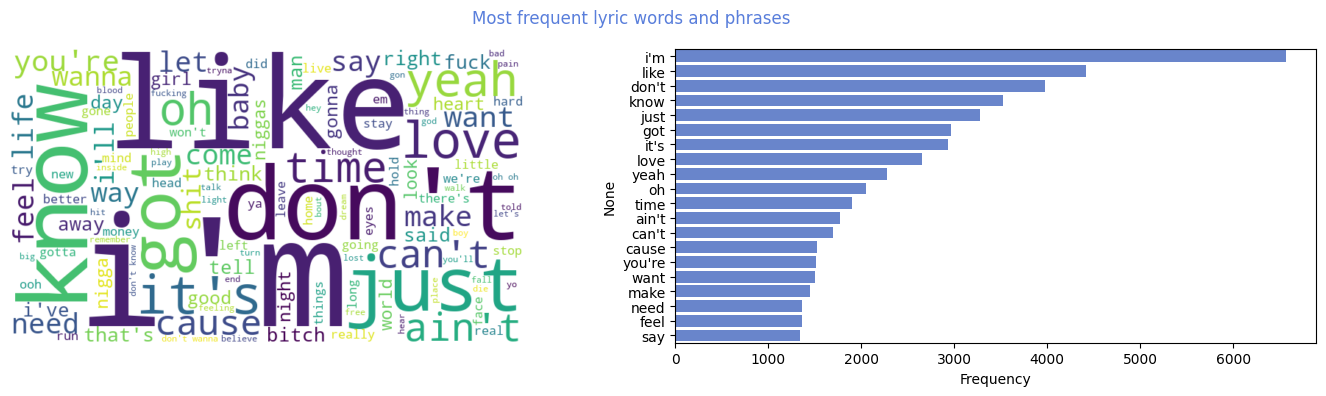

In [3]:
frequencies, top_terms = sentiment.summarize_vocabulary(df_sample)
sentiment.plot_vocabulary(frequencies, top_terms)

<h2 style="color: #4166c4; font-weight: 400;">5. Sentiment scoring <a id="sentiment-scoring"></a></h2>

Every cleaned line in every song is scored by VADER and TextBlob.
In VADER, the original text based on grammar and a specific lexicon is analysed, while in TextBlob we calculate polarity and subjectivity. Then, the tool outputs line-by-line scores (including duplicate lines) alongside the overall song averages.

### 5.1 Line-level Scores <a id="line-level-scores"></a>


In [4]:
df_lines, df_song = sentiment.score_lyric_lines(df_sample)
print(f"Scored {len(df_lines):,} lyric lines across both versions.")
display(df_lines.head())

Scored 155,861 lyric lines across both versions.


,song_key,line_version,line_index,line_position,line_text,vader_neg,vader_neu,vader_pos,vader_compound,textblob_polarity,textblob_subjectivity,vader_label,textblob_label
0,0,all_lines,0,0.000000,I just think it's funny,0.0,0.58,0.42,0.4404,0.25,1.0,Positive,Positive
1,0,all_lines,1,0.021277,The way the lights all turn green,0.0,1.00,0.00,0.0000,-0.20,0.3,Neutral,Negative
2,0,all_lines,2,0.042553,As I'm driving to your house,0.0,1.00,0.00,0.0000,0.00,0.0,Neutral,Neutral
3,0,all_lines,3,0.063830,I just think it's funny,0.0,0.58,0.42,0.4404,0.25,1.0,Positive,Positive
4,0,all_lines,4,0.085106,How many times you texted me,0.0,1.00,0.00,0.0000,0.50,0.5,Neutral,Positive


### 5.2 Song-level scores and tool agreement <a id="song-level-scores"></a>

The song score is the mean of its line scores, so every retained line contributes equally within a song. 
The primary summaries use the repeated-line-deduplicated version. 

Agreement measures describe similarity between the tools, not accuracy against human judgements.

,VADER,TextBlob
sentiment,,
Negative,0.245221,0.117949
Neutral,0.369697,0.565967
Positive,0.385082,0.316084


Spearman correlation (VADER vs TextBlob): 0.606
Label agreement: 55.3%
Cohen's kappa: 0.302


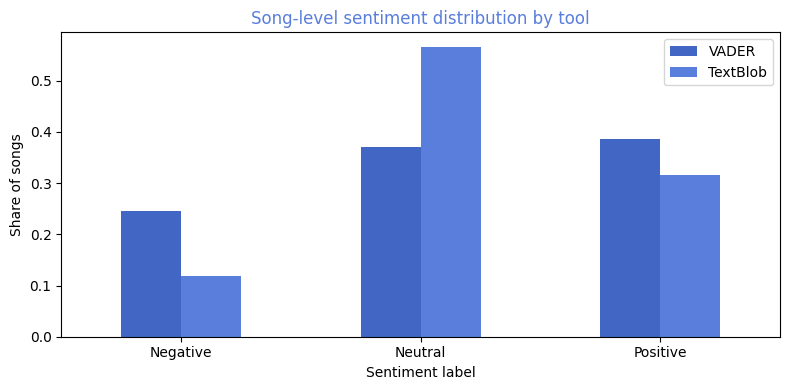

In [5]:
df_song_primary = df_song[df_song["line_version"].eq("deduplicated")].copy()
distribution, agreement = sentiment.get_sentiment_agreement(df_song_primary)
display(distribution.rename_axis("sentiment"))
print(f"Spearman correlation (VADER vs TextBlob): {agreement['spearman_correlation']:.3f}")
print(f"Label agreement: {agreement['label_agreement']:.1%}")
print(f"Cohen's kappa: {agreement['cohen_kappa']:.3f}")
sentiment.plot_sentiment_distribution(distribution)

### 5.3 How the scores are computed <a id="scoring-rules"></a>

VADER adds word valences from its lexicon, adjusts them for negation, intensifiers, capitals and punctuation, and normalises the sum. 

neg, neu and pos are proportions of the text, not probabilities, and compound is the normalised valence from -1 to +1. TextBlob's polarity is the mean polarity of the phrases it assesses. A lexicon-only sum matches VADER on simple words but loses the context rules.

In [6]:
vader_table, textblob_table = sentiment.explain_scoring_rules()
display(vader_table)
display(textblob_table)

,neg,neu,pos,compound,lexicon_only
I love this song.,0.000,0.417,0.583,0.6369,0.6369
I do not love this song.,0.402,0.598,0.000,-0.5216,0.6369
I really love this song.,0.000,0.471,0.529,0.6697,0.6369
I LOVE this song!!!,0.000,0.341,0.659,0.7788,0.6369


,text,assessments,textblob_polarity
0,good,"[([good], 0.7, 0.6000000000000001, None)]",7.000000e-01
1,not good,"[([not, good], -0.35, 0.6000000000000001, None)]",-3.500000e-01
2,The beat was good but the lyrics were bad.,"[([good], 0.7, 0.6000000000000001, None), ([ba...",5.551115e-17
3,table chair,[],0.000000e+00


### 5.4 Whole-song versus line-mean scoring <a id="aggregation"></a>

The song score above is the mean of its line scores. Scoring the whole song as one text is another reasonable choice, but VADER's normalisation compresses large sums, so the two need not agree. High correlation does not mean identical values, so the mean absolute difference is shown as well.

In [7]:
df_whole = sentiment.score_whole_songs(df_sample, df_song_primary)
display(sentiment.summarize_aggregation(df_whole))
print(
    "Pearson, VADER vs TextBlob (line mean): "
    f"{df_song_primary['vader_compound'].corr(df_song_primary['textblob_polarity']):.3f}"
)

,pearson_r,mean_abs_difference
VADER,0.741925,0.714692
TextBlob,0.894068,0.080197


Pearson, VADER vs TextBlob (line mean): 0.577


### 5.5 Where the tools disagree <a id="disagreement"></a>

Agreement statistics say how similar the tools are, not why they differ. The songs with the largest VADER versus TextBlob gap are read directly to see which language each tool handles differently.

In [8]:
disagreements = sentiment.top_disagreements(df_song_primary, df_sample)
display(disagreements.drop(columns=["song_key", "lyrics_clean"]))
for row in disagreements.itertuples():
    print(f"\n{row.title} - {row.artist}")
    print("\n".join(row.lyrics_clean.splitlines()[:6]))

,title,artist,vader_compound,textblob_polarity
0,Issues,Sip Tha Kid,-0.9983,-0.036924
1,Flexing,Interstate flexer,-0.9836,-0.058249
2,All I Need,Dro Ottie,-0.7865,0.125000



Issues - Sip Tha Kid
Verse 1 (Sip Tha Kid): "Live it up, all I'm thinking is bucks, would have more friends but it's so hard to trust. I'm only down for me and this New World team, hoes flocking around wanna know what it mean, I tell her pay attention, baby girl just listen. Realness to a t, I ain't thinking bout Lipton. I'm finna get me a Benz, spend some bread with my kin and then let my hair blow in the wind, but that's the hard part. Niggas don't wanna see you live, my whole life I been trying to stay on some better shit, you work hard hell you can be the president, they wonder how I kill these niggas with no evidence. Making that money fast, that's how you hurt they ass, they gon be sick when you pull up in that new Jag, and tell them you ain't got nuthin on these and you can get it too if you grind like this. Chorus: They say I got issues, but they don't really know what I been through. They say that I'm insane, they wanna know what's thinking in my brain, man I'm just me X2. Ve

<h2 style="color: #4166c4; font-weight: 400;">6. Sentiment patterns <a id="sentiment-patterns"></a></h2>

### 6.1 Genre, artist, and decade <a id="metadata"></a>

The following summaries give each song equal weight.

Artist averages include artists with at least three sampled songs and, decade averages include plausible release years and decades with at least ten sampled songs.

,song_count,vader_mean,textblob_mean,positive_share
tag,,,,
rap,616,-0.029059,0.004572,0.232143
rock,402,0.002521,0.015570,0.310945
pop,885,0.043458,0.037337,0.497175
misc,90,0.046141,0.034263,0.411111
rb,97,0.056093,0.042841,0.494845
country,55,0.075668,0.060154,0.600000


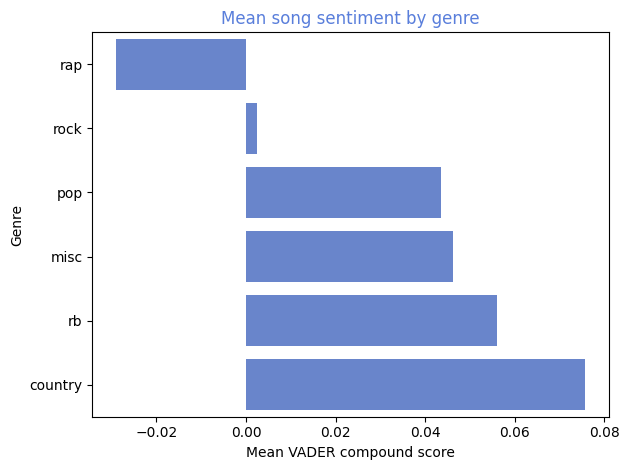

Artists with the most sampled songs:


,song_count,vader_mean,textblob_mean
artist,,,
Bing Crosby,3,0.148350,0.050493
Emily Dickinson,3,0.024347,-0.024679


Sentiment by decade:


,song_count,vader_median,textblob_median
decade,,,
1960.0,26,0.079018,0.061824
1970.0,38,0.066395,0.052266
1980.0,66,0.076815,0.039608
1990.0,133,0.044029,0.027922
2000.0,291,0.016193,0.023333
2010.0,1118,0.013184,0.017758
2020.0,458,0.009548,0.016324


In [9]:
genre_summary, artist_summary, decade_summary = sentiment.summarize_metadata(
    df_song_primary
)
display(genre_summary)
sentiment.plot_genre_sentiment(genre_summary)
print("Artists with the most sampled songs:")
display(artist_summary.sort_values("song_count", ascending=False).head(15))
print("Sentiment by decade:")
display(decade_summary)

### 6.2 Within-song arc <a id="song-arc"></a>

To map the emotional arc, each song is split chronologically into ten equal parts (bins). We average the scores within each part for every song, then average them across all songs. This prevents longer tracks from distorting the overall trend.

,vader_compound,textblob_polarity
position_bin,,
0,0.005479,0.013505
1,0.018122,0.024121
2,0.016768,0.024125
3,0.019772,0.030953
4,0.017307,0.021486
5,0.021049,0.022833
6,0.010961,0.027862
7,0.019128,0.024535
8,0.028108,0.032155


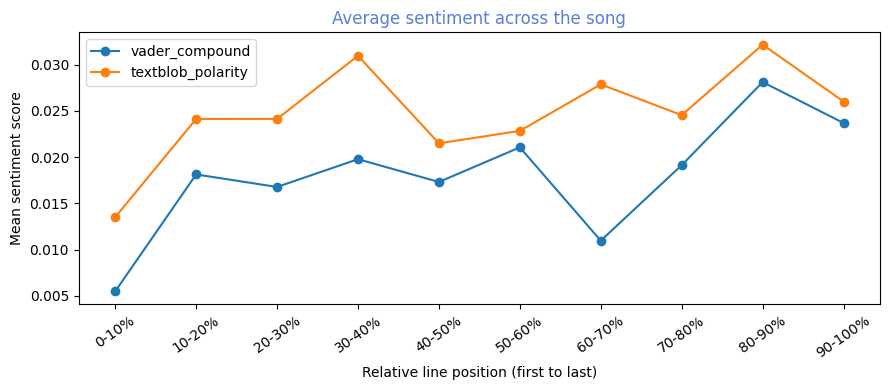

In [10]:
arc_summary = sentiment.summarize_song_arc(df_lines)
display(arc_summary)
sentiment.plot_song_arc(arc_summary)

<h2 style="color: #4166c4; font-weight: 400;">7. Sentiment over time <a id="time-trends"></a></h2>

Years outside 1900–2024 are excluded as implausible for this dataset. Annual medians are shown only for years with at least eight sampled songs. The five-year rolling median uses calendar years, so missing years are not treated as adjacent observations.

Songs excluded for implausible release years: 6


,song_count,vader_median,textblob_median,vader_rolling_median
year,,,,
2013,102.0,0.000000,0.018151,0.019808
2014,95.0,0.019808,0.021256,0.015676
2015,170.0,0.043968,0.023265,0.015676
2016,78.0,0.015676,0.013617,0.015676
2017,151.0,0.014581,0.017893,0.014581
2018,191.0,-0.006033,0.014658,0.010867
2019,196.0,0.010867,0.014755,0.009643
2020,233.0,0.009643,0.015000,0.009643
2021,194.0,0.004704,0.015536,0.010255


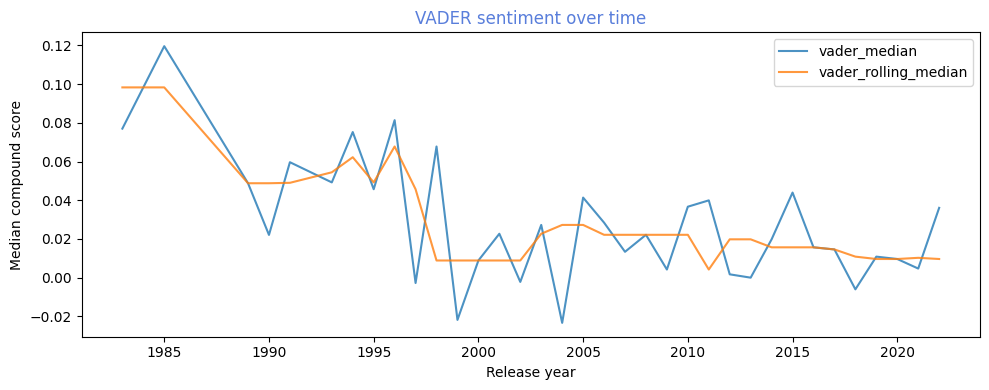

In [11]:
year_summary, excluded_years = sentiment.summarize_sentiment_over_time(
    df_song_primary
)
print(f"Songs excluded for implausible release years: {excluded_years:,}")
display(year_summary.tail(10))
sentiment.plot_sentiment_over_time(year_summary)

The blue line (vader_median) shows the exact annual sentiment median, reflecting short-term, year-to-year emotional fluctuations and noise in song lyrics. In contrast, the orange line (vader_rolling_median) calculates a moving multi-year average that smooths out these annual spikes and dips. While the blue line highlights specific volatile years—such as sharp drops in 1999 or 2004—the orange line reveals the underlying macro-trend. Together, they show that despite short-term annual variations, the sentiment experienced a clear long-term shift from high positivity in the 1980s toward a near-neutral emotional baseline from 2000 onward.

<h2 style="color: #4166c4; font-weight: 400;">8. Themes and emotions <a id="themes-emotions"></a></h2>

TF-IDF and Non-Negative Matrix Factorization (NMF) are applied to extract exploratory topics from lyrics, while the NRC Lexicon calculates emotion proportions across genres. TF-IDF weights word importance within each song, allowing NMF to cluster text into statistical topic groups. These outputs represent high-weight keywords rather than verified theme labels. Similarly, the NRC Lexicon tracks emotional distributions via direct word-matching frequencies. These metrics reflect literal textual data rather than psychological assessments of the authors.

Exploratory topics:


,,song_count,vader_mean,textblob_mean
topic_id,topic_terms,,,
4,"time, life, away, it's, world, come, day, like",800,0.011808,0.022832
1,"bitch, niggas, nigga, fuck, shit, like, ain't, got",366,-0.064356,-0.008329
0,"don't, yeah, know, wanna, just, want, baby, don't wanna",325,0.030543,0.028022
5,"i'm, like, just, it's, i'll, can't, cause, that's",280,0.016659,0.018109
3,"love, love love, baby, heart, you're, know, forever, want",226,0.117091,0.074886
2,"oh, oh oh, yeah, oh yeah, baby, she's, ohh, beautiful",148,0.056646,0.042888


NRC emotion proportions by genre:


,anger,anticipation,disgust,fear,joy,sadness,surprise,trust
tag,,,,,,,,
country,0.052529,0.100151,0.040188,0.065233,0.134375,0.085265,0.054854,0.110982
misc,0.053619,0.143045,0.044955,0.078413,0.084792,0.073193,0.039109,0.107072
pop,0.060168,0.106579,0.041435,0.085320,0.111846,0.094138,0.050547,0.097081
rap,0.100211,0.079119,0.077783,0.102054,0.074960,0.094080,0.044722,0.087289
rb,0.066770,0.098749,0.039651,0.077398,0.122160,0.090160,0.053537,0.093404
rock,0.070613,0.102843,0.053395,0.102503,0.087358,0.099058,0.046984,0.091696


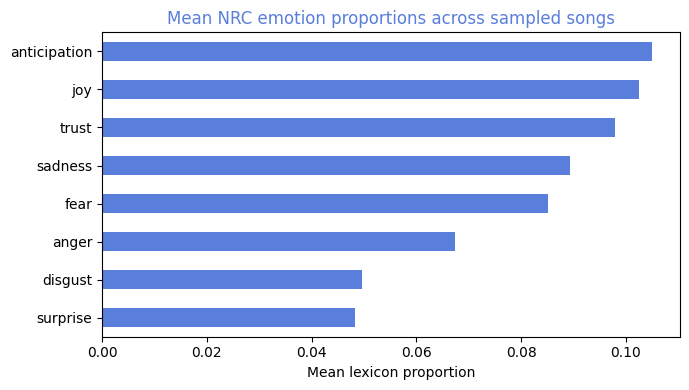

In [12]:
theme_summary, emotion_summary = sentiment.summarize_themes_and_emotions(
    df_sample, df_song_primary
)
print("Exploratory topics:")
display(theme_summary)
print("NRC emotion proportions by genre:")
display(emotion_summary)
sentiment.plot_emotions(emotion_summary)

<h2 style="color: #4166c4; font-weight: 400;">9. Subjectivity <a id="subjectivity"></a></h2>

TextBlob subjectivity is the mean of the line-level subjectivity scores. Lyrics are expected to be subjective, so a high or narrow distribution does not establish that the sentiment estimates are accurate.

,textblob_subjectivity
count,2145.000000
mean,0.214720
std,0.098433
min,0.000000
25%,0.146175
50%,0.204545
75%,0.270238
max,0.633333


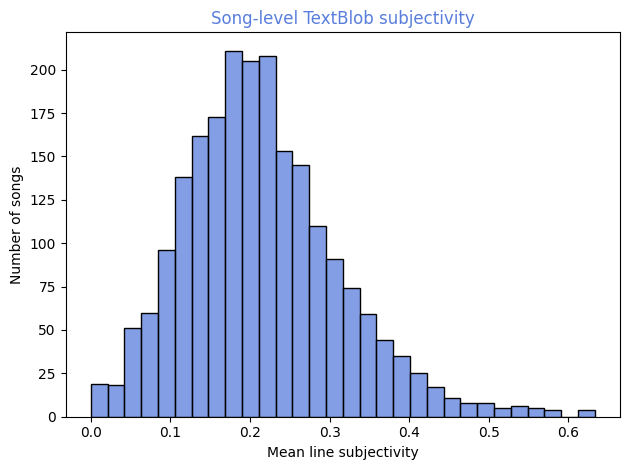

In [13]:
subjectivity_summary = sentiment.summarize_subjectivity(df_song_primary)
display(subjectivity_summary.to_frame("textblob_subjectivity"))
sentiment.plot_subjectivity(df_song_primary)

<h2 style="color: #4166c4; font-weight: 400;">10. Validation and robustness <a id="validation"></a></h2>

The dataset has no human sentiment labels, so validation consists of simple cleaning checks, inspection of example scores, comparison between tools, and a repeated-chorus sensitivity check. Review ambiguous language predictions before making language-specific claims.

In [14]:
cleaning_example = sentiment.validate_cleaning()
print("Cleaning checks passed. Example cleaned text:")
print(cleaning_example)

print("Example line scores:")
display(sentiment.score_validation_examples())

chorus_sensitivity = sentiment.summarize_chorus_sensitivity(df_song)
display(
    chorus_sensitivity[["absolute_score_change", "label_changed"]].describe(
        include="all"
    )
)
print(
    "Songs whose VADER label changes when repeated lines are kept: "
    f"{chorus_sensitivity['label_changed'].mean():.1%}"
)

ambiguous_language = df_candidates[
    ~(
        df_candidates["language"].eq("en")
        & df_candidates["language_confidence"].ge(sentiment.LANGUAGE_CONFIDENCE)
    )
].sort_values("language_confidence")
display(
    ambiguous_language[
        ["title", "artist", "language", "language_confidence"]
    ].head(10)
)

Cleaning checks passed. Example cleaned text:
I DON'T want to go!!!
Maybe tomorrow...
Example line scores:


,line,vader_compound,textblob_polarity
0,I love this song!,0.6696,0.625
1,I do not love this song.,-0.5216,-0.250
2,I NEVER said I hated you!!!,0.6421,-1.000
3,I'm gonna be alright...,0.2500,0.000


line_version,absolute_score_change,label_changed
count,2145.000000,2145
unique,NaN,2
top,NaN,False
freq,NaN,1875
mean,0.024102,NaN
std,0.033768,NaN
min,0.000000,NaN
25%,0.001975,NaN
50%,0.012863,NaN
75%,0.032515,NaN


Songs whose VADER label changes when repeated lines are kept: 12.6%


,title,artist,language,language_confidence
92980,Sha-La Love You,Lancelot Link and the Evolution Revolution,ca,0.571426
29998,Enter In,The Blackbyrds,nl,0.571427
67624,You said,Iriss,cy,0.571427
77497,Dark Knight,OCTOBERSFULLMOON,en,0.714283
461,Chemicals,The Paperviews,tl,0.714284
75111,Bug Bites,Del Water Gap,en,0.714285
105699,Run,Air,en,0.714285
104532,Peng,Sama Blake,en,0.714286
104995,Never Let You Go,LEV in the Wild,fr,0.857141


<h2 style="color: #4166c4; font-weight: 400;">11. Questions for a deeper understanding <a id="questions"></a></h2>


### 11.1. Are there changes in the predominant sentiments of a genre over the years? <a id="12-1"></a>

In [15]:
# Filter valid release years and calculate mean VADER sentiment per genre across decades
df_valid_years = df_song_primary[df_song_primary['year'].between(1970, 2024)].copy()
df_valid_years['decade'] = (df_valid_years['year'] // 10 * 10).astype(int)

genre_decade_sentiment = df_valid_years.groupby(['decade', 'tag'])['vader_compound'].mean().unstack()
display(genre_decade_sentiment.round(3))

tag,country,misc,pop,rap,rb,rock
decade,,,,,,
1970,0.134,-0.268,0.099,NaN,0.055,0.039
1980,0.102,NaN,0.069,-0.082,0.105,0.055
1990,0.055,0.005,0.057,-0.071,0.135,0.040
2000,0.058,-0.018,0.018,-0.035,0.039,-0.017
2010,0.069,0.038,0.044,-0.027,0.049,-0.004
2020,0.095,0.178,0.050,-0.028,0.059,-0.001


Sentiment declined mainly between the 1980s and the 2000s in pop, rock and R&B and then stabilised, while country dipped and recovered. Rap is the only genre that is consistently negative, and it became slightly less negative over time (from -0.082 in the 1980s to -0.028 in the 2020s). Genre rankings change between decades, and some cells, such as misc in the 1970s, contain very few songs.

### 11.2  What are the predominant sentiments in the lyrics of the songs of a specific musical genre? <a id="12-2"></a>

In [16]:
# Sentiment label distribution (%) and overall mean compound score by genre
genre_sentiment_dist = pd.crosstab(
    df_song_primary['tag'], 
    df_song_primary['vader_label'], 
    normalize='index'
).reindex(columns=['Negative', 'Neutral', 'Positive'], fill_value=0) * 100

genre_sentiment_dist['mean_compound'] = df_song_primary.groupby('tag')['vader_compound'].mean()
display(genre_sentiment_dist.round(2))

vader_label,Negative,Neutral,Positive,mean_compound
tag,,,,
country,10.91,29.09,60.00,0.08
misc,25.56,33.33,41.11,0.05
pop,16.05,34.24,49.72,0.04
rap,35.71,41.07,23.21,-0.03
rb,16.49,34.02,49.48,0.06
rock,29.60,39.30,31.09,0.00


The prodominat positive sentiments are Country and Pop.
R&B is also largely positive and Rock is balanced between positive and negative, while Rap is the only genre with a negative mean compound score (-0.03)

### 11.3.  Does a song's sentiment impact its popularity within a genre (or even across genres)? <a id="12-3"></a>

In [17]:
# Merge song sentiment with popularity (views from df_sample)
df_popularity = df_song_primary.merge(df_sample[['song_key', 'views']], on='song_key')

# Correlation between sentiment score and view count
spearman_corr = df_popularity['vader_compound'].corr(df_popularity['views'], method='spearman')
print(f"Spearman correlation between sentiment and views: {spearman_corr:.3f}")

# Median views across sentiment categories by genre
views_by_sentiment = df_popularity.groupby(['tag', 'vader_label'])['views'].median().unstack().reindex(columns=['Negative', 'Neutral', 'Positive'])
display(views_by_sentiment)

Spearman correlation between sentiment and views: 0.015


vader_label,Negative,Neutral,Positive
tag,,,
country,612.5,207.0,185.0
misc,14.0,15.5,24.0
pop,88.0,132.0,112.5
rap,102.5,54.0,56.0
rb,91.0,170.0,53.5
rock,48.0,140.5,79.0


No, Spearman rank correlation between sentiment valence and view count is near zero, therefore, the sentiment does not impact popularity within or across genres.

### 11.4. Within a specific genre, do debut albums by artists display a significantly different emotional signature compared to their later, more established work? <a id="12-4"></a>

In [18]:
# Identify artist debut release year from the complete dataset (df_train)
artist_debut_year = df_train.groupby('artist')['year'].min()
is_debut = df_song_primary['year'] == df_song_primary['artist'].map(artist_debut_year)

df_debut = df_song_primary.assign(
    career_stage=np.where(is_debut, 'Debut Year', 'Later Years')
)

# Compare average emotional tone (VADER compound) between debut and later releases
debut_comparison = df_debut.groupby(['tag', 'career_stage'])['vader_compound'].agg(['count', 'mean']).unstack()
display(debut_comparison.round(3))

count                   mean            
career_stage Debut Year Later Years Debut Year Later Years
tag                                                       
country              24          31      0.092       0.063
misc                 69          21      0.041       0.065
pop                 565         320      0.033       0.062
rap                 452         164     -0.029      -0.030
rb                   79          18      0.060       0.038
rock                266         136     -0.008       0.022

Differences between debut-year and later songs are small and inconsistent. Country (0.092 vs 0.063) and R&B (0.060 vs 0.038) are slightly more positive in the debut year, pop (0.033 vs 0.062), rock (-0.008 vs 0.022) and misc (0.041 vs 0.065) slightly less, and rap is unchanged. Debut is approximated by the artist's earliest year in the dataset, since there is no album information, and some groups are small.

### 11.5. Are modern lyrics generally becoming more positive, negative, or polarized over time compared to previous decades <a id="12-5"></a>

In [19]:
# Group songs from 1970s to 2020s by decade
df_decades = df_song_primary[df_song_primary['year'].between(1970, 2024)].copy()
df_decades['decade'] = (df_decades['year'] // 10 * 10).astype(int)

# Track sentiment trajectory, sentiment proportions, and emotional polarization (spread / std)
decade_trends = df_decades.groupby('decade').agg(
    song_count=('vader_compound', 'count'),
    mean_sentiment=('vader_compound', 'mean'),
    negative_pct=('vader_label', lambda s: (s == 'Negative').mean() * 100),
    neutral_pct=('vader_label', lambda s: (s == 'Neutral').mean() * 100),
    positive_pct=('vader_label', lambda s: (s == 'Positive').mean() * 100),
    polarization_std=('vader_compound', 'std'),
)
display(decade_trends.round(2))

,song_count,mean_sentiment,negative_pct,neutral_pct,positive_pct,polarization_std
decade,,,,,,
1970,38,0.06,7.89,36.84,55.26,0.15
1980,66,0.06,18.18,21.21,60.61,0.14
1990,133,0.04,15.79,36.84,47.37,0.12
2000,291,0.01,26.12,38.83,35.05,0.14
2010,1118,0.01,26.21,37.30,36.49,0.14
2020,458,0.01,25.33,37.77,36.90,0.12


Based on the dataset, modern lyrics have generally become less positive over time when comparing the 1970s to the 2020s, while polarization has remained consistent. Specifically, the mean sentiment score dropped from 0.06 in the 1970s down to 0.01 by the 2020s. At the same time, the polarization standard deviation stayed relatively stable, moving only slightly from 0.15 in the 1970s to 0.12 in the 2020s.

### 11.6. How do themes of love, heartbreak, anger, and triumph distribute themselves emotionally across different genres? <a id="12-7"></a>

In [20]:
# Lyrical markers for love, heartbreak, anger, and triumph
theme_patterns = {
    'love': r'\b(?:love|lover|loving|adore)\b',
    'heartbreak': r'\b(?:heartbreak|broken heart|broke my heart|crying|tears|lonely)\b',
    'anger': r'\b(?:anger|angry|hate|furious|mad|rage)\b',
    'triumph': r'\b(?:win|winning|champion|victory|triumph|proud)\b'
}

df_themes = df_song_primary.merge(df_sample[['song_key', 'lyrics_clean']], on='song_key')

# Average sentiment score for each theme across genres
theme_scores = {}
for theme, pattern in theme_patterns.items():
    mask = df_themes['lyrics_clean'].str.contains(pattern, case=False, regex=True, na=False)
    theme_scores[theme] = df_themes[mask].groupby('tag')['vader_compound'].mean()

display(pd.DataFrame(theme_scores).round(3))

,love,heartbreak,anger,triumph
tag,,,,
country,0.106,0.089,-0.068,0.061
misc,0.078,0.053,0.079,0.119
pop,0.088,0.037,-0.028,0.067
rap,0.006,0.015,-0.042,-0.002
rb,0.097,0.055,-0.008,0.018
rock,0.053,-0.005,-0.062,-0.005


Love and triumph skew positive in most genres, and anger is negative in country, rock, rap and pop. Heartbreak keywords are mildly positive in most genres, probably because those songs also contain love-related words, so the keyword set captures mixed-tone lyrics rather than pure sadness. Rap stays close to neutral for love, heartbreak and triumph. The positive anger score for misc (0.079) is likely a small-sample or keyword artefact.

### 11.7. Does vocabulary richness and lexical diversity correlate with higher or lower sentiment extremity? <a id="12-8"></a>

In [21]:
def get_ttr(text):
    words = str(text).lower().split()
    return len(set(words)) / max(len(words), 1)

df_lex = df_song_primary.merge(df_sample[['song_key', 'lyrics_clean']], on='song_key')
df_lex['ttr'] = df_lex['lyrics_clean'].map(get_ttr)
df_lex['sentiment_extremity'] = df_lex['vader_compound'].abs()

# Pearson correlation overall and per genre
overall_corr = df_lex['ttr'].corr(df_lex['sentiment_extremity'])
print(f"Overall Pearson correlation (TTR vs Sentiment Extremity): {overall_corr:.3f}")

genre_corr = pd.Series(
    {genre: group['ttr'].corr(group['sentiment_extremity']) for genre, group in df_lex.groupby('tag')}
)
display(genre_corr.round(3).to_frame('ttr_extremity_correlation'))

Overall Pearson correlation (TTR vs Sentiment Extremity): 0.016


,ttr_extremity_correlation
country,-0.260
misc,-0.035
pop,0.051
rap,-0.033
rb,-0.022
rock,0.016


Vocabulary richness and lexical diversity (TTR) do not show a strong or consistent overall correlation with sentiment extremity. In most genres, the correlation is virtually zero, including misc (-0.035), rap (-0.033), r&b (-0.022), rock (0.016), and pop (0.051). Country music is the sole exception, exhibiting a moderate negative correlation of -0.260, which indicates that in country lyrics, higher lexical diversity slightly correlates with lower sentiment extremity. Overall, using a broader vocabulary does not inherently make song lyrics more emotionally extreme across most genres.

### 11.8. Do crossover songs exhibit a more neutral sentiment profile compared to genre-pure tracks? <a id="12-9"></a>

In [22]:
# Identify multi-genre crossover artists (artists with songs across >1 genre tag in df_train)
crossover_artists = set(df_train.groupby('artist')['tag'].nunique().loc[lambda s: s > 1].index)

df_crossover = df_song_primary.assign(
    artist_type=np.where(df_song_primary['artist'].isin(crossover_artists), 'Crossover Artist', 'Genre-Pure Artist')
)

# Compare neutrality share and sentiment extremity between crossover and genre-pure tracks
crossover_comparison = df_crossover.groupby('artist_type').agg(
    song_count=('vader_compound', 'count'),
    mean_compound=('vader_compound', 'mean'),
    neutral_share=('vader_label', lambda s: (s == 'Neutral').mean()),
    mean_extremity=('vader_compound', lambda s: s.abs().mean())
)
display(crossover_comparison.round(3))

,song_count,mean_compound,neutral_share,mean_extremity
artist_type,,,,
Crossover Artist,427,0.034,0.377,0.091
Genre-Pure Artist,1718,0.012,0.368,0.098


Crossover songs do not exhibit a significantly more neutral sentiment profile compared to genre-pure tracks. 
As we can see, crossover artists have a neutral share of 0.377 (37.7%) compared to 0.368 (36.8%) for genre-pure artists, representing only a marginal difference of about 0.9 percentage points. Furthermore, their emotional extremity levels are nearly identical, with mean extremity scoring 0.091 for crossover artists and 0.098 for genre-pure artists. While crossover artists display a slightly higher mean compound score (0.034 versus 0.012), overall both groups maintain very similar neutral shares and emotional intensities.   

### 11.9. Does sentiment help classify the genre of a song? <a id="11-9"></a>

Genre is the only label available in the data, so it is used as a classification target. Sentiment features (mean, spread and share of positive and negative lines for VADER and TextBlob, plus subjectivity) are compared with a TF-IDF vocabulary model and with both combined, using 5-fold stratified cross-validation and macro-F1 because the genres are imbalanced. This tests whether the emotional tone carries information about genre, and whether it adds anything beyond the words themselves.

In [25]:
import importlib
import tools.sentiment_analysis as sentiment
sentiment = importlib.reload(sentiment)

df_features = sentiment.build_sentiment_features(df_lines, df_song_primary)
genre_classification = sentiment.evaluate_genre_classification(df_features, df_sample)
display(genre_classification.round(3))

,accuracy,macro_f1,macro_f1_std
Majority-class baseline,0.413,0.097,0.000
Sentiment features only,0.253,0.195,0.033
TF-IDF only,0.533,0.399,0.024
TF-IDF + sentiment,0.519,0.379,0.024


The majority-class baseline, which always predicts pop, reaches a macro-F1 of 0.097 and an accuracy of 0.413, so it is the floor that any useful model must beat. Sentiment features alone reach a macro-F1 of 0.195, about twice the baseline and roughly three fold-to-fold standard deviations above it, so emotional tone carries some information about genre. Its accuracy (0.253) is lower than the baseline's because the classifier is class-balanced and therefore predicts the smaller genres more often, which is why macro-F1 is the fairer metric here. The vocabulary model is far stronger, with a macro-F1 of 0.399 against 0.195 for sentiment alone, so words identify genre much better than emotional tone does. Adding the sentiment features to the vocabulary model does not help: macro-F1 changes from 0.399 to 0.379, a gap smaller than the cross-validation variation of about 0.024, so sentiment adds no measurable information beyond the words themselves. Overall, emotional tone is a weak signal of genre, which agrees with the modest differences in mean sentiment between genres found earlier, where rap was the only clearly negative genre.

<h2 style="color: #4166c4; font-weight: 400;">12. Conclusion <a id="conclusion"></a></h2>

This analysis compared VADER and TextBlob on 2,145 English songs sampled from six genres, scoring 155,861 cleaned lines. Both tools give small average scores (VADER 0.016, TextBlob 0.025), so most lyrics sit close to neutral and differences between groups should be read as tendencies, not sharp contrasts.

The two tools agree only partly. Their song scores are positively related (Spearman 0.606) and they assign the same label to 55.3% of songs, with a Cohen's kappa of 0.302, which indicates fair agreement beyond chance. Part of the gap comes from their behaviour: TextBlob labels 57% of songs as neutral against 37% for VADER, and VADER reacts to negation, capitals and punctuation that TextBlob handles less well. Scoring a whole song as one text matches the line-mean score for TextBlob (r = 0.89) but not for VADER (r = 0.74, mean difference 0.71), because VADER's compound saturates towards ±1 on long text. This supports scoring line by line, and the songs where the tools disagree most appear to be long texts scored as a single block.

Genre differences are modest but consistent. Rap is the only genre with a negative mean VADER score (-0.029) and has the largest share of negative songs (36%), while country (0.076), R&B (0.056) and pop (0.043) are the most positive, and rock sits close to zero. Country, R&B and misc have fewer than 100 songs each, so their averages are less certain. The topic model agrees: the most positive topic is built around love words (0.117) and the most negative around explicit language (-0.064).

Sentiment drifted towards neutral over time. Median scores were around 0.07 to 0.08 until the 1980s and about 0.01 from the 2000s onwards, and the share of negative songs rose from 8% in the 1970s to about 26%. The shift happens mainly in the 1990s and 2000s and then stabilises, while polarisation changes little. Because the sample is dominated by the 2010s and the genre mix changes by decade, part of this shift may reflect composition. Within songs, scores rise slightly from the first tenth (0.005) to the last tenth (0.024), a small effect.

The deeper questions show little structure. Sentiment is not associated with popularity (Spearman 0.015), lexical diversity is unrelated to sentiment extremity overall (r = 0.016), debut and later songs differ only slightly and inconsistently, and crossover artists are not more neutral than genre-pure artists (37.7% against 36.8% neutral songs). Keeping repeated chorus lines changes the VADER label of 12.6% of songs, so the deduplication choice matters but does not overturn the results. Sentiment features predict genre above the majority baseline (macro-F1 0.195 against 0.097) but add nothing to a vocabulary model (0.379 against 0.399).

These findings are limited by general-purpose English lexicons, which miss irony, slang and metaphor: VADER scores "I NEVER said I hated you!!!" as positive (0.64). There are no human labels, so agreement between tools is not accuracy, and group differences are descriptive and not causal. Overall, the lyrics in this sample are mildly positive on average, rap is the most negative genre, and sentiment has moved towards neutral since the 1990s.